![Categorical Encoding Techniques Infographic.png](<attachment:Categorical Encoding Techniques Infographic.png>)
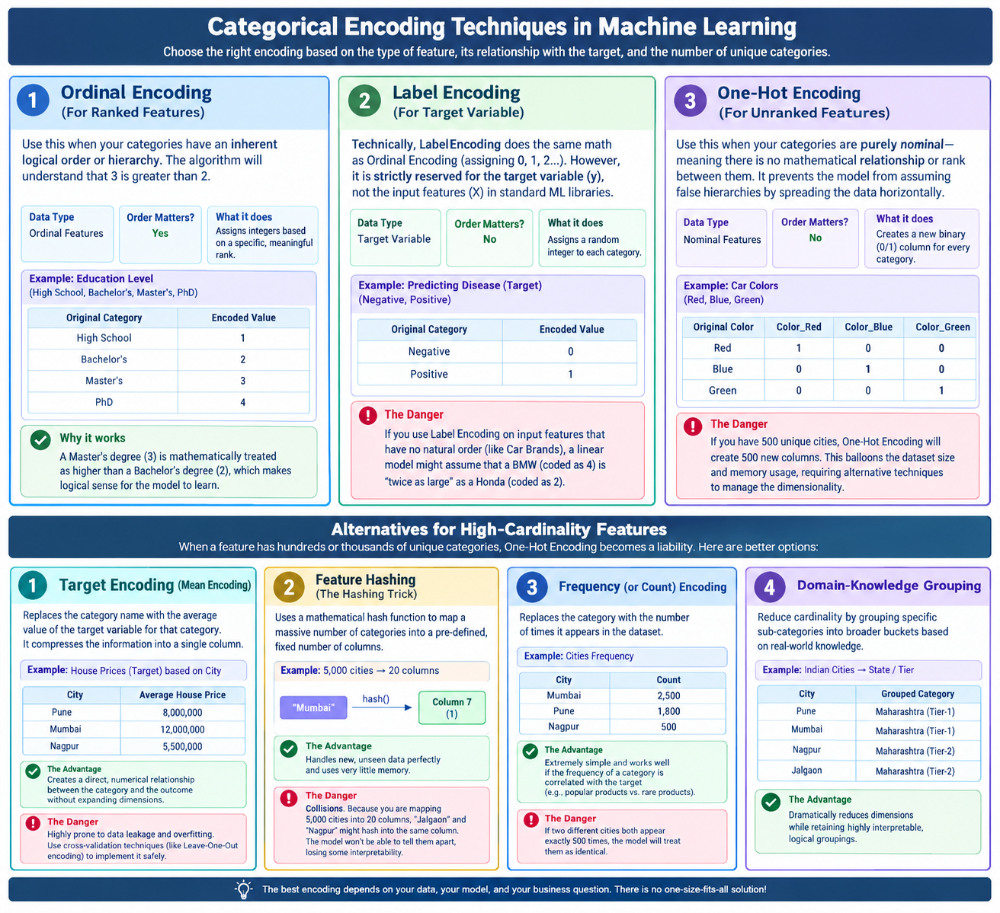

# Encoding Techniques in Machine Learning — Correct Definitions, Examples, and Use Cases

Encoding is a data preprocessing technique used to convert categorical data (text or labels) into numerical values so that machine learning algorithms can process it.

There are two main types of categorical data:

- Ordinal data: Categories have a meaningful order, such as Low, Medium, and High.
- Nominal data: Categories have no meaningful order, such as Red, Blue, and Green.

## 1. Comparison of Encoding Techniques

| Encoding technique        | Best suited for                                        | How it works                                                           | Example use case                       |
| ------------------------- | ------------------------------------------------------ | ---------------------------------------------------------------------- | -------------------------------------- |
| Ordinal Encoding          | Ordered categorical features                           | Assigns numbers according to a meaningful ranking                      | Education level, customer satisfaction |
| Label Encoding            | Usually the target variable (`y`)                      | Assigns an integer to each target class                                | Predicting Yes/No or Cat/Dog           |
| One-Hot Encoding          | Unordered categorical features                         | Creates separate binary columns for categories                         | Car brand, color, city                 |
| Target Encoding           | High-cardinality categorical features                  | Replaces each category with a target-based statistic, usually the mean | House prices by city                   |
| Feature Hashing           | Very high-cardinality features                         | Maps categories into a fixed number of columns using a hash function   | Product IDs, text features             |
| Frequency/Count Encoding  | Categorical features with useful frequency information | Replaces each category with its occurrence count or frequency          | Product popularity, customer IDs       |
| Domain-Knowledge Grouping | Categories that can be grouped logically               | Combines categories into broader, meaningful groups                    | Cities grouped by state or tier        |

## 2. Ordinal Encoding

Definition: Ordinal encoding converts categorical values into numerical values according to their meaningful order or ranking.

Example: Customer satisfaction

| Category | Encoded value |
| -------- | ------------- |
| Low      | 1             |
| Medium   | 2             |
| High     | 3             |

Use cases:

- Education: School, Bachelor's, Master's, PhD.
- Satisfaction: Poor, Average, Good, Excellent.
- Product size: Small, Medium, Large.

Important: Define the category order explicitly. The numerical distances do not necessarily represent equal real-world differences between categories.

## 3. Label Encoding

Definition: Label encoding assigns an integer to each distinct class in a categorical target variable, converting class labels into numbers.

Example: Predicting whether a patient has a disease.

| Disease status | Encoded value |
| -------------- | ------------- |
| Negative       | 0             |
| Positive       | 1             |

Example with multiple classes:

| Animal | Encoded value |
| ------ | ------------- |
| Cat    | 0             |
| Dog    | 1             |
| Bird   | 2             |

Use cases:

- Disease prediction: Positive or Negative.
- Customer churn prediction: Churn or No Churn.
- Image classification: Cat, Dog, Bird.

Important correction: Label encoding is commonly used for the target variable (`y`), particularly with scikit-learn's `LabelEncoder`. It is not strictly forbidden for input features, but arbitrary integer labels can introduce a misleading numerical order. For nominal input features, One-Hot Encoding is often more appropriate.

## 4. One-Hot Encoding

Definition: One-hot encoding converts each category into a separate binary column, assigning `1` when the category is present and `0` otherwise.

Example: Car colors.

| Original color | Color_Red | Color_Blue | Color_Green |
| -------------- | --------- | ---------- | ----------- |
| Red            | 1         | 0          | 0           |
| Blue           | 0         | 1          | 0           |
| Green          | 0         | 0          | 1           |
| Red            | 1         | 0          | 0           |

Use cases:

- Car brands: BMW, Honda, Toyota.
- Payment methods: Cash, UPI, Card.
- Product categories: Clothing, Electronics, Furniture.

Advantages: Avoids imposing an arbitrary numerical ranking on nominal categories.

Limitation: A feature with hundreds or thousands of categories may create many columns. Sparse representations and alternatives such as feature hashing or target encoding can help.

## 5. Target Encoding (Mean Encoding)

Definition: Target encoding replaces each category with a statistic calculated from the target variable for that category, usually the mean for a regression target or a binary classification target.

Example: Predicting house prices using city.

| City   | House price (₹) |
| ------ | --------------- |
| Pune   | 8,000,000       |
| Pune   | 6,000,000       |
| Mumbai | 12,000,000      |
| Mumbai | 10,000,000      |

Calculate the average house price for each city:

| City   | Average price | Encoded value |
| ------ | ------------- | ------------- |
| Pune   | ₹7,000,000    | 7,000,000     |
| Mumbai | ₹11,000,000   | 11,000,000    |

The city name is replaced with its average target value.

Use cases:

- Predicting house prices from cities.
- Predicting sales from product categories.
- Predicting customer churn from high-cardinality customer attributes.

Advantages: Represents many categories in a single numerical column.

Risk: Target leakage and overfitting, especially for categories with very few records. Use training-fold-based encoding, smoothing, and appropriate cross-validation. Calculate encodings from training data only, then apply them to validation and test data.

## 6. Feature Hashing (Hashing Trick)

Definition: Feature hashing uses a hash function to map categorical values into a fixed number of numerical features.

Example: You have 5,000 unique product IDs but want to represent them using only 20 columns.

- Input: `Product_A`, `Product_B`, `Product_C`
- Output: A fixed-size feature representation.
- Each category is assigned to a column using a hash function.

Use cases:

- Large product catalogs.
- Text classification and natural language processing.
- Large-scale recommendation systems.

Advantages: Fixed memory requirements and the ability to process unseen categories without maintaining a complete category-to-column mapping.

Limitation: Different categories can map to the same column. This is called a hash collision, and it can reduce the information available to the model.

## 7. Frequency or Count Encoding

Definition: Frequency encoding replaces a category with how often it occurs in a dataset. Count encoding uses the number of occurrences; frequency encoding commonly uses the proportion of occurrences.

Example:

| City    | Count encoding | Frequency encoding |
| ------- | -------------- | ------------------ |
| Pune    | 500            | 0.50               |
| Mumbai  | 300            | 0.30               |
| Jalgaon | 200            | 0.20               |

Assume the dataset contains 1,000 records.

- Pune count: 500; frequency: \\(500/1000 = 0.50\\).
- Mumbai count: 300; frequency: \\(300/1000 = 0.30\\).
- Jalgaon count: 200; frequency: \\(200/1000 = 0.20\\).

Use cases:

- Product popularity analysis.
- Customer transaction datasets.
- High-cardinality features such as cities or product categories.

Advantages: Simple, memory-efficient, and adds only one numerical column.

Limitation: Different categories with the same count receive the same encoded value, even if their relationship with the target differs.

## 8. Domain-Knowledge Grouping

Definition: Domain-knowledge grouping combines multiple categories into broader groups using real-world knowledge or business rules.

Example: Grouping cities by state.

| City      | State       |
| --------- | ----------- |
| Pune      | Maharashtra |
| Mumbai    | Maharashtra |
| Nagpur    | Maharashtra |
| Ahmedabad | Gujarat     |
| Surat     | Gujarat     |

Instead of encoding every city separately, the model can use the `State` feature.

Another example is grouping cities into business-defined tiers:

| City    | Tier   |
| ------- | ------ |
| Mumbai  | Tier 1 |
| Pune    | Tier 1 |
| Nagpur  | Tier 2 |
| Jalgaon | Tier 2 |

Note: City tiers depend on the chosen classification scheme, so these assignments are illustrative.

Use cases:

- Grouping cities by state, region, or market tier.
- Grouping job titles into departments.
- Combining rare product categories into an `Other` category.

Advantages: Reduces the number of unique categories and can improve interpretability.

Limitation: Poorly chosen groups can remove useful information.

--

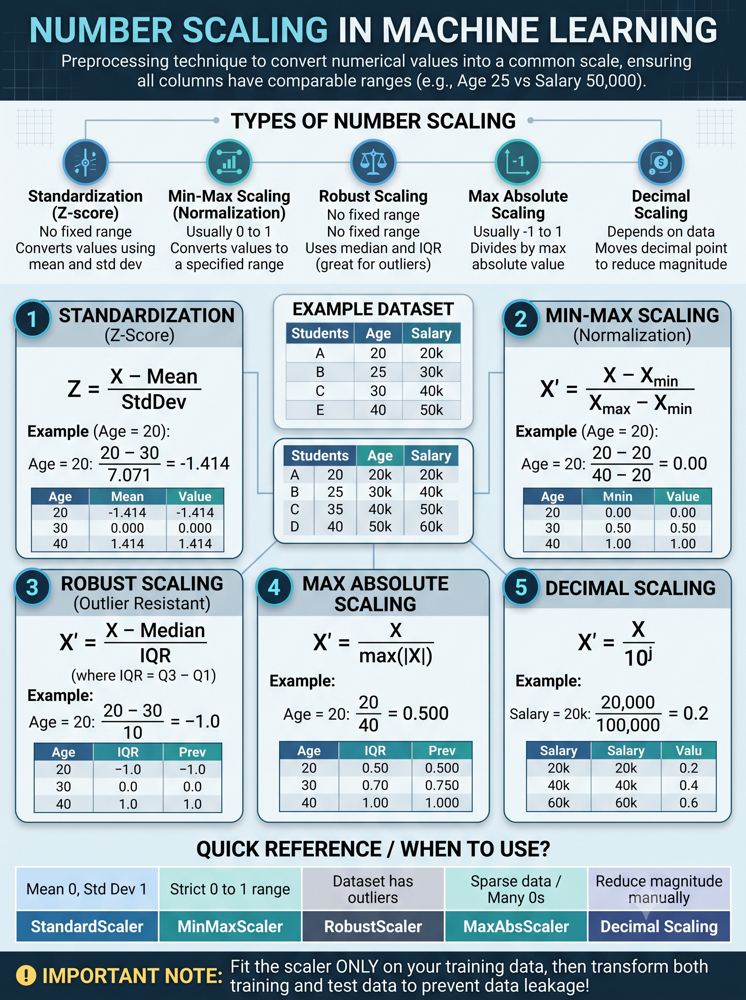

In [ ]:
# Page URL --> https://www.kaggle.com/datasets/arshmankhalid/bank-marketing-ml-ready-dataset
# Name Data Set --> Bank Marketing ML Ready Dataset

import kagglehub
import pandas as pd
from pathlib import Path

# Download the Kaggle dataset
path = kagglehub.dataset_download(
    "arshmankhalid/bank-marketing-ml-ready-dataset"
)

# Find downloaded CSV and Excel files
dataset_path = Path(path)

files = [
    file for file in dataset_path.rglob("*")
    if file.suffix.lower() in [".csv", ".xlsx", ".xls"]
]

# Display available files
print("Available files:")
for file in files:
    print(file.name)

# Load the first available file
if not files:
    raise FileNotFoundError("No CSV or Excel file found.")

file_path = files[0]

if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path)
else:
    df = pd.read_excel(file_path)

# Display dataset information
print("\nDataset loaded successfully!")
print("File:", file_path.name)
print("Shape:", df.shape)

display(df.head())
display(df.info())


Available files:
Bank_Marketing_Original_Data.csv
Bank_Marketing_Ready_to_TRAIN_MODEL.csv
description.csv

Dataset loaded successfully!
File: Bank_Marketing_Original_Data.csv
Shape: (45211, 17)


,Age,Job,Marital,Education,Default,Balance,Housing,Loan,contact,Day,Month,Duration,Campaign,Pdays,Previous,poutcome,TARGET
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Age        45211 non-null  int64
 1   Job        45211 non-null  str  
 2   Marital    45211 non-null  str  
 3   Education  45211 non-null  str  
 4   Default    45211 non-null  str  
 5   Balance    45211 non-null  int64
 6   Housing    45211 non-null  str  
 7   Loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   Day        45211 non-null  int64
 10  Month      45211 non-null  str  
 11  Duration   45211 non-null  int64
 12  Campaign   45211 non-null  int64
 13  Pdays      45211 non-null  int64
 14  Previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  TARGET     45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


None

In [23]:
text_column = df.select_dtypes(include="object").columns

for col in text_column:
    display(f"column names --> {col}")
    display(df[col].unique())

C:\Users\Admin\AppData\Local\Temp\ipykernel_14672\1123409379.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_column = df.select_dtypes(include="object").columns


'column names --> Job'

<StringArray>
[   'management',    'technician',  'entrepreneur',   'blue-collar',
       'unknown',       'retired',        'admin.',      'services',
 'self-employed',    'unemployed',     'housemaid',       'student']
Length: 12, dtype: str

'column names --> Marital'

<StringArray>
['married', 'single', 'divorced']
Length: 3, dtype: str

...

<StringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr',
 'sep']
Length: 12, dtype: str

'column names --> poutcome'

<StringArray>
['unknown', 'failure', 'other', 'success']
Length: 4, dtype: str

'column names --> TARGET'

<StringArray>
['no', 'yes']
Length: 2, dtype: str

#### Ordinal Column ----> Education---> OrdinalEncoder 
#### Label Encoder ---> TARGET ----> LabelEncoder
#### Nominal Column --> Married,...

In [24]:
df.columns

Index(['Age', 'Job', 'Marital', 'Education', 'Default', 'Balance', 'Housing',
       'Loan', 'contact', 'Day', 'Month', 'Duration', 'Campaign', 'Pdays',
       'Previous', 'poutcome', 'TARGET'],
      dtype='str')

In [26]:
df["Education"].unique()

<StringArray>
['tertiary', 'secondary', 'unknown', 'primary']
Length: 4, dtype: str

In [27]:
ordinal_data = df[["Education"]]

from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[['unknown', 'primary', 'secondary', 'tertiary']])

ordinal_data_trans = oe.fit_transform(ordinal_data)
ordinal_data_trans

array([[3.],
       [2.],
       [2.],
       ...,
       [2.],
       [2.],
       [2.]], shape=(45211, 1))

In [28]:
lable_data = df["TARGET"]

from sklearn.preprocessing import LabelEncoder
la = LabelEncoder()

lable_data_trans = la.fit_transform(lable_data)
lable_data_trans

array([0, 0, 0, ..., 1, 0, 0], shape=(45211,))

In [33]:
nominal_data = df[['Job','Marital','Education', 'Default', 'Housing', 'Loan', 'contact', 'Month', 'poutcome']]
nominal_data

from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()

nominal_data_trans = ohe.fit_transform(nominal_data)
nominal_data_trans

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 406899 stored elements and shape (45211, 44)>

In [ ]:
standard_data = df.select_dtypes(include='number')
standard_data

from sklearn.preprocessing import StandardScaler
ss = StandardScaler()

standard_data_trans = ss.fit_transform(standard_data)
standard_data_trans

array([[ 1.60696496,  0.25641925, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       [ 0.28852927, -0.43789469, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       [-0.74738448, -0.44676247, -1.29847633, ..., -0.56935064,
        -0.41145311, -0.25194037],
       ...,
       [ 2.92540065,  1.42959305,  0.14341818, ...,  0.72181052,
         1.43618859,  1.05047333],
       [ 1.51279098, -0.22802402,  0.14341818, ...,  0.39902023,
        -0.41145311, -0.25194037],
       [-0.37068857,  0.52836436,  0.14341818, ..., -0.24656035,
         1.4761376 ,  4.52357654]], shape=(45211, 7))

In [43]:
from sklearn.compose import ColumnTransformer

ColumnTransformer(transformers=[
                                ('ordinal', ordinal_data_trans),
                                ('lable', lable_data_trans), 
                                ('nominal', nominal_data_trans), 
                                ('standard', standard_data_trans)
                                ], 
                  remainder='passthrough')

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('lable', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,ordinal,"array([[3.], ...pe=(45211, 1))"
,lable,"array([0, 0, ...hape=(45211,))"
,nominal,"<Compressed S...e (45211, 44)>"
,standard,"array([[ 1.60...pe=(45211, 7))"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string

# OR

In [78]:
from sklearn.preprocessing import  OrdinalEncoder, OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_cols = df.select_dtypes(include='number').columns.tolist()
numeric_cols

transformer = ColumnTransformer(transformers=[
    ('ordinal',OrdinalEncoder(categories=[['unknown', 'primary', 'secondary', 'tertiary']]), ['Education'] ),
    ('Onehot', OneHotEncoder(handle_unknown='ignore'), ['Job','Marital','Education', 'Default', 'Housing', 'Loan', 'contact', 'Month', 'poutcome']),
    ('Standart', StandardScaler(), numeric_cols )
],
remainder='passthrough'
)

transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('Onehot', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` a

In [87]:
X = df.iloc[:,:-1 ]
X_transformed = transformer.fit_transform(X)
X_transformed

# Or
# X = df.drop(columns = ['TARGET'])

array([[ 3.        ,  0.        ,  0.        , ..., -0.56935064,
        -0.41145311, -0.25194037],
       [ 2.        ,  0.        ,  0.        , ..., -0.56935064,
        -0.41145311, -0.25194037],
       [ 2.        ,  0.        ,  0.        , ..., -0.56935064,
        -0.41145311, -0.25194037],
       ...,
       [ 2.        ,  0.        ,  0.        , ...,  0.72181052,
         1.43618859,  1.05047333],
       [ 2.        ,  0.        ,  1.        , ...,  0.39902023,
        -0.41145311, -0.25194037],
       [ 2.        ,  0.        ,  0.        , ..., -0.24656035,
         1.4761376 ,  4.52357654]], shape=(45211, 52))

In [81]:
lable_data = df["TARGET"]

from sklearn.preprocessing import LabelEncoder
la = LabelEncoder()

Y = la.fit_transform(lable_data)
Y

array([0, 0, 0, ..., 1, 0, 0], shape=(45211,))

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Save the transformed features
X_transformed = transformer.fit_transform(X)

from sklearn.preprocessing import LabelEncoder
lable_data = df["TARGET"]
la = LabelEncoder()
Y = la.fit_transform(lable_data)

# 2. Split the data (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_transformed, 
    Y, 
    test_size=0.2, 
    random_state=42 # Ensures you get the same split every time you run it
)

In [84]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the machine learning model
model = RandomForestClassifier(random_state=42)

# 2. Train (fit) the model using the training data
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [85]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Make predictions on the unseen test data
y_pred = model.predict(X_test)

# 2. Check the accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# 3. View a detailed performance report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 90.46%

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      7952
           1       0.67      0.40      0.51      1091

    accuracy                           0.90      9043
   macro avg       0.80      0.69      0.73      9043
weighted avg       0.89      0.90      0.89      9043



# Untransformed dataset

In [86]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Isolate only the numeric columns to avoid string conversion errors
X_numeric = df.select_dtypes(include='number')

# Ensure the target variable isn't accidentally included in your features
if 'TARGET' in X_numeric.columns:
    X_numeric = X_numeric.drop(columns=['TARGET'])

# 2. Split this raw numeric data
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_numeric, 
    Y, # This is the encoded target variable you created earlier
    test_size=0.2, 
    random_state=42
)

# 3. Train a baseline model
baseline_model = RandomForestClassifier(random_state=42)
baseline_model.fit(X_train_raw, y_train)

# 4. Make predictions
y_pred_raw = baseline_model.predict(X_test_raw)

# 5. Evaluate the baseline performance
print("--- Baseline Model (Numeric Columns Only) ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_raw) * 100:.2f}%\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_raw))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_raw))

--- Baseline Model (Numeric Columns Only) ---
Accuracy Score: 89.21%

Confusion Matrix:
[[7692  260]
 [ 716  375]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7952
           1       0.59      0.34      0.43      1091

    accuracy                           0.89      9043
   macro avg       0.75      0.66      0.69      9043
weighted avg       0.88      0.89      0.88      9043

